In [ ]:
%matplotlib inline

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from skimage.io import imread
# Write yor imports here

# Statistics Exercise
## Statistical Distributions. Properties of distributions. Applications of Probability and Statistics in Computer Science

### Problem 1. Plotting a Single Distribution. Digits in $\pi$ and $e$
We expect that the decimal digits in $\pi$ and $e$ will be randomly distributed and there's no reason for any digit to dominate over others. Let's verify this.

Using an algorithm, the first 10 004 digits of $\pi$ and $e$ were generated:
$$
\pi = 3.(141592 \dots 5678)5667
$$
$$
e = 2.(718281 \dots 6788)5674
$$

The 10 000 digits in brackets were counted. You can see the results in `digits.dat`. Each column corresponds to one digit from 0 to 9. The first row is for $\pi$ and the second row is for $e$.

How are these digits distributed? Are the two distributions different?

**Note:** The dataset is **not properly formatted** to work easily. You can transpose it. Now, digit counts will be in rows and variables - in columns. 
```python
digits = pd.read_table("digits.dat", header = None).T
```

You can also specify column names like this:
```python
digits.columns = ["pi", "e"]
```

Also note that **we are not creating the histogram of the distribution**. We already have the counts, we need to plot them. In a sense, the histogram has already been calculated.

To do this, we can create a "bar chart" (using `plt.bar()`). We have to provide values for the x-axis and y-axis. For the x-axis, we have the numbers 0 through 9 (we can use the *index* of the dataset like this: `digits.index`). For the y-axis, we need to plot the digit counts directly.

We can see that even the simplest datasets sometimes need a bit of preprocessing. This is always the case when we're working with data.

In [16]:
# Write your code here
pd.read_table("digits.dat", header = None).T
digits.columns = ["pi", "e"]

In [17]:
digits

,pi,e
0,968,974
1,1026,989
2,1021,1004
3,974,1008
4,1012,982
5,1046,992
6,1021,1079
7,970,1008
8,948,996
9,1014,968


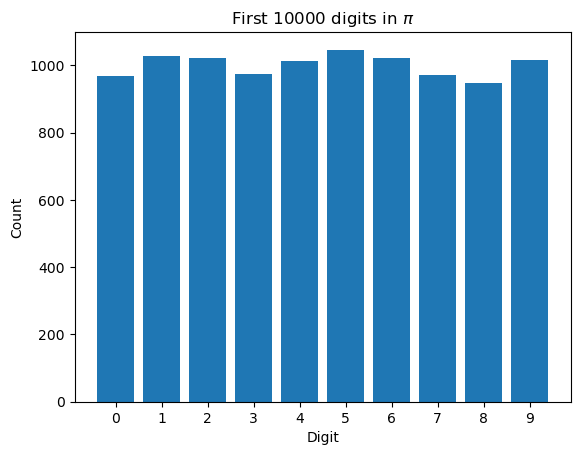

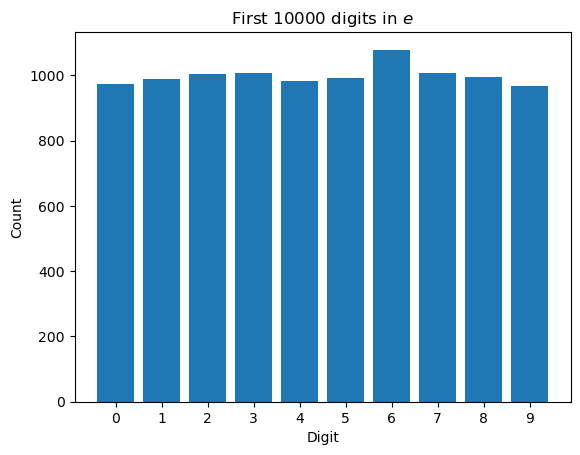

In [20]:
# Write your code here
plt.bar(digits.index, digits["pi"])
plt.xlabel("Digit")
plt.ylabel("Count")
plt.xticks(digits.index)
plt.title("First 10000 digits in $\\pi$")
plt.show()

plt.bar(digits.index, digits["e"])
plt.xlabel("Digit")
plt.ylabel("Count")
plt.xticks(digits.index)
plt.title("First 10000 digits in $e$")
plt.show()

Let's try something else. Scientists have measured the percentage of silica ($\text{SiO}_2$, sand / glass) for 22 meteors. You can find it in `silica.dat`. How are these distributed? What is a "typical" percentage? Is there such percentage at all?

Print the mean, standard deviation (you can use the biased or unbiased formula), skewness and kurtosis of the distribution. What do these numbers tell you? How do they relateto the shape of the distribution? Can you characterize the distribution better? (An idea would be to characterize different parts of it on their own, as if they're different distributions.)

In [32]:
# Write your code here
silica = pd.read_table("silica.dat", header = None)
silica.columns = ["concentration"]

In [33]:
silica

,concentration
0,20.77
1,22.56
2,22.71
3,22.99
4,26.39
5,27.08
6,27.32
7,27.33
8,27.57
9,27.81


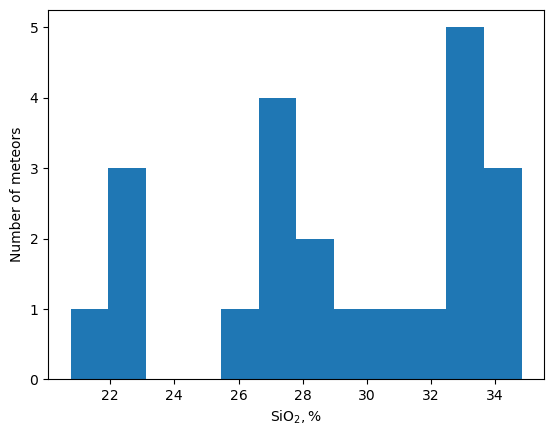

In [36]:
plt.hist(silica["concentration"], bins = 12)
plt.xlabel("$\\text{SiO}_2, \\%$")
plt.ylabel("Number of meteors")
plt.show()

### Problem 2. Categorical Variables. Comparing Categories
In addition to numeric variables (like age and salary), in statistics we also use **categorical variables**. These are descriptions of quality (as opposed to quantity). Such variables can be gender, smoker / non-smoker, results of a medical study (healthy / not healthy), colors (red, green, blue), etc. To plot values of categories, we use *bar charts*. Since category names can be long, it's sometimes useful to plot the lines horizontally.

<p style="color: #d9534f"><strong>There is a very significant difference between histograms and bar charts. Histograms are used to plot the frequency distribution of one numeric variable. Bar charts are used to plot categorical variables - how each value compares to other values.</strong></p>

The dataset `budget.dat` contains the figures for the eight main items in the US budget for 1978 and 1979 in billions
of dollars.

Display the two budgets separately. Use `xlabel()` (or `ylabel()` if your plot is horizontal) to write the names of each category. You can use [this](https://matplotlib.org/examples/pylab_examples/barchart_demo.html) and [this](https://matplotlib.org/examples/pylab_examples/barchart_demo2.html) examples as a guide.

Create another variable which shows the difference in budget $\Delta b = b_{1979} - b_{1978}$. Add this variable to the dataset (find out how). Plot it. How does the budget differ?

Since the numbers are different, a better comparison will be if we convert them to percentages of the total budget. Create two more variables for 1978 and 1979 and add them to the dataset. Plot these now. Also plot the difference in percentage, like you did before.

In [39]:
# Write your code here
budget = pd.read_table("budget.dat")

In [40]:
budget

,Category,1978,1979
0,Military spending,107.6,117.8
1,Social security,103.9,115.1
2,Health care,44.3,49.7
3,Debt service,43.8,49.0
4,Welfare,43.7,44.9
5,Education,27.5,30.4
6,Energy,19.9,21.8
7,Veteran's benefits,18.9,19.3


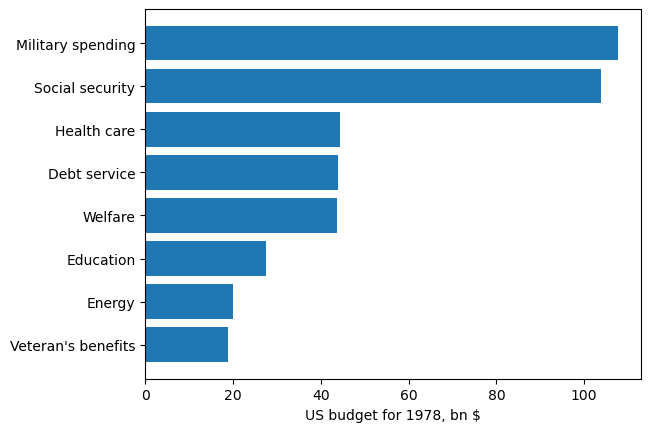

In [49]:
budget = budget.sort_values("1978")
plt.barh(budget["Category"], budget["1978"])
plt.xlabel("US budget for 1978, bn $")
plt.show()

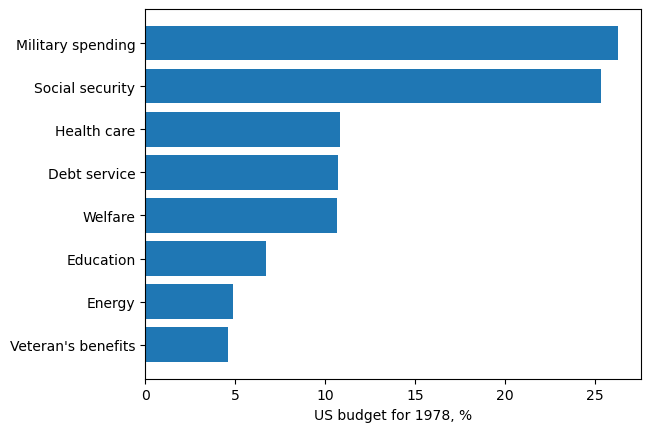

In [50]:
budget = budget.sort_values("1978")
plt.barh(budget["Category"], budget["1978"] / budget["1978"].sum() * 100)
plt.xlabel("US budget for 1978, %")
plt.show()

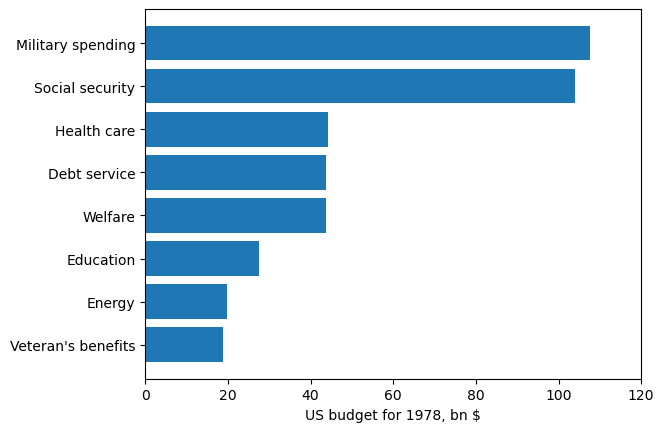

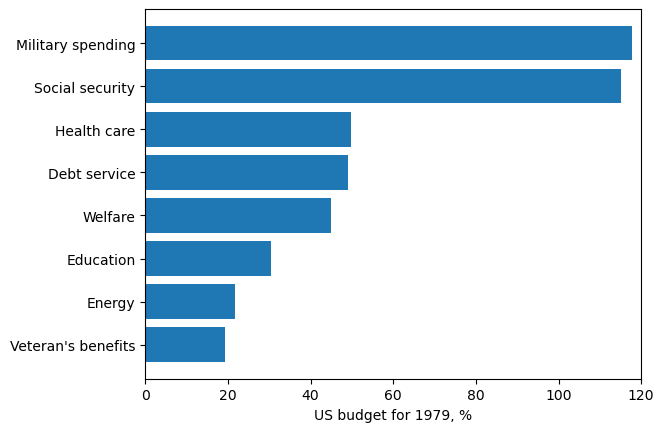

In [53]:
budget = budget.sort_values("1978")
plt.barh(budget["Category"], budget["1978"])
plt.xlabel("US budget for 1978, bn $")
plt.xlim(0, 120)
plt.show()

budget = budget.sort_values("1979")
plt.barh(budget["Category"], budget["1979"])
plt.xlabel("US budget for 1979, %")
plt.xlim(0, 120)
plt.show()

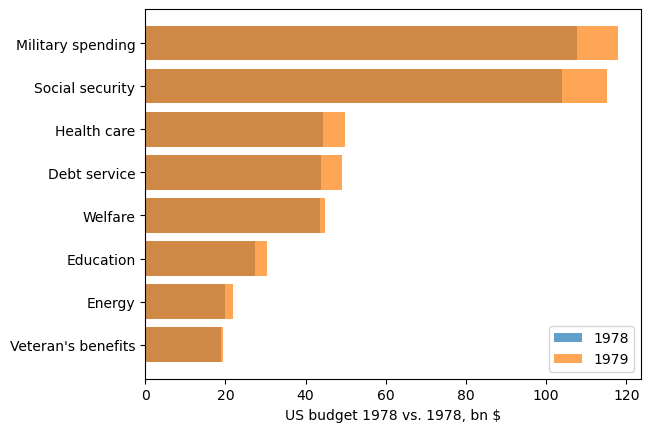

In [54]:
budget = budget.sort_values("1978")
plt.barh(budget["Category"], budget["1978"], label = "1978", alpha = 0.7)
plt.barh(budget["Category"], budget["1979"], label = "1979", alpha = 0.7)
plt.xlabel("US budget 1978 vs. 1978, bn $")
plt.legend()
plt.show()

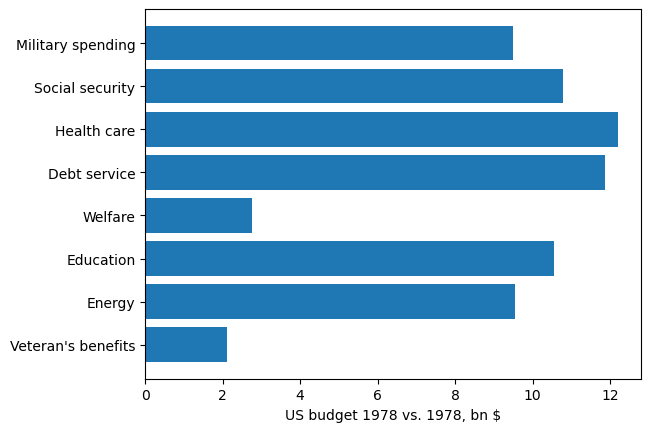

In [55]:
budget = budget.sort_values("1978")
plt.barh(budget["Category"], (budget["1979"] - budget["1978"]) / budget["1978"] * 100)
plt.xlabel("US budget 1978 vs. 1978, bn $")
plt.show()

### Problem 3. Correlations between Variables. Alcohol and Tobacco Usage
The dataset `alcohol_tobacco.dat` shows the average weekly household spending, in British pounds, on tobacco products and alcoholic beverages for each of the 11 regions of Great Britain.

Create a scatter plot. Print the correlation coefficient. You can use the **correlation matrix** (find out how).

There's a major outlier. Which one is it?

Remove the outlier from the dataset (find out how). Calculate the correlation coefficient once again. It should be much higher.

This example is useful to show what an outlier is, and how an outlier can influence the results of an experiment.

**Note:** Be careful with outliers. Sometimes they indicate human error (e.g. human height 1588 cm is obviously wrong) but sometimes they indicate important patterns in the data. Should you remove, replace, or leave them is a difficult question and should be answered separately for each dataset.

In [56]:
# Write your code here
alcohol_tobacco = pd.read_table("alcohol_tobacco.dat")

In [57]:
alcohol_tobacco

,Region,Alcohol,Tobacco
0,North,6.47,4.03
1,Yorkshire,6.13,3.76
2,Northeast,6.19,3.77
3,East Midlands,4.89,3.34
4,West Midlands,5.63,3.47
5,East Anglia,4.52,2.92
6,Southeast,5.89,3.20
7,Southwest,4.79,2.71
8,Wales,5.27,3.53
9,Scotland,6.08,4.51


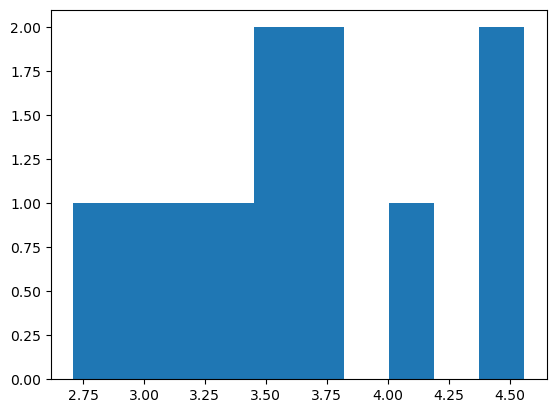

In [58]:
plt.hist(alcohol_tobacco["Tobacco"])
plt.show()

In [59]:
alcohol_tobacco[["Alcohol", "Tobacco"]].corr()

,Alcohol,Tobacco
Alcohol,1.000000,0.223572
Tobacco,0.223572,1.000000


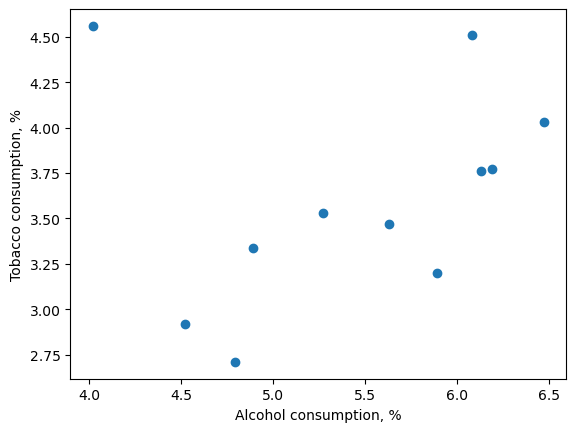

In [61]:
plt.scatter(alcohol_tobacco["Alcohol"], alcohol_tobacco["Tobacco"])
plt.xlabel("Alcohol consumption, %")
plt.ylabel("Tobacco consumption, %")
plt.show()

In [63]:
alcohol_tobacco[
    (alcohol_tobacco["Alcohol"] < 4.4) &
    (alcohol_tobacco["Tobacco"] > 4.25)
]

,Region,Alcohol,Tobacco
10,Northern Ireland,4.02,4.56


In [64]:
alcohol_tobacco_filtered = alcohol_tobacco.drop(index = 10)

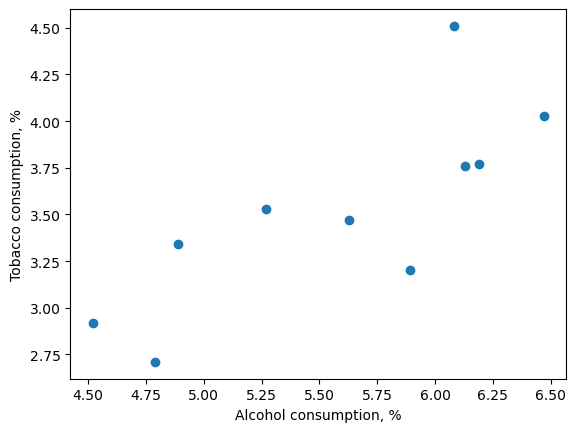

In [65]:
plt.scatter(alcohol_tobacco_filtered["Alcohol"], alcohol_tobacco_filtered["Tobacco"])
plt.xlabel("Alcohol consumption, %")
plt.ylabel("Tobacco consumption, %")
plt.show()

In [66]:
alcohol_tobacco_filtered[["Alcohol", "Tobacco"]].corr()

,Alcohol,Tobacco
Alcohol,1.000000,0.784287
Tobacco,0.784287,1.000000


### Problem 4. Simulation
Another prediction technique based on statistics, is simulation. This means recreating a system's parameters and running the experiment on a computer instead of running it in real life. Simulation can give us many insights. It's useful for prediction, "what-if" analysis, etc. It's also very useful if we have very limited "real experimentation" resources and want to narrow down our possibilities.

Let's see how we can simulate the profit of a grocery shop.

The profit is dependent on the customers and what items they buy. Let's assume that the number of customers per months follows a normal distribution with mean 500 and standard deviation 20.

$$ C \sim N(500, 20) $$

In the shop, there are several items, each having a different popularity. The popularity represents the probability of buying each item.

| Item               | Price | Popularity |
|--------------------|-------|------------|
| Bread              | 0.99  | 0.5        |
| Milk               | 2.89  | 0.15       |
| Eggs, dozen        | 2.00  | 0.2        |
| Chicken fillet, kg | 6.39  | 0.15       |

Each customer buys *exactly one* article at random. Each customer will generate an expected profit equal to $\text{price} . \text{popularity}$. Total profit: sum of all profits.

In [3]:
def get_customer_profit():
    n = np.random.random()
    if n <= 0.5:
        return 0.99
    elif n < 0.65:
        return 2.89
    elif n <= 0.85:
        return 2
    else:
        return 6.39

In [4]:
days = 1000
def run_simulation():
    profits = []
    for day in range(days):
        customers = np.floor(np.random.normal(500, 20))
        profit = sum([get_customer_profit() for c in np.arange(customers)])
        profits.append(profit)
    return profits

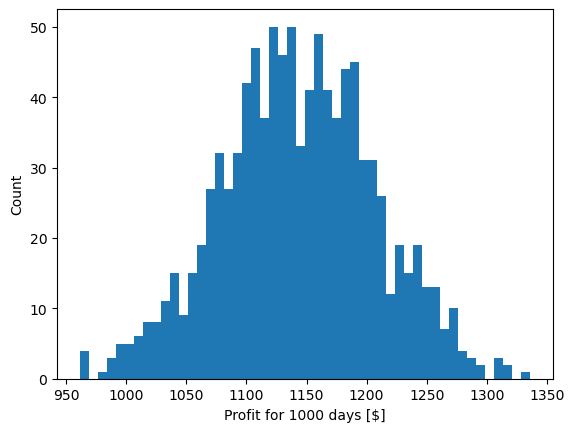

In [5]:
profits = run_simulation()
plt.hist(profits, bins = 50)
plt.xlabel("Profit for " + str(days) + " days [$]")
plt.ylabel("Count")
plt.show()

In [67]:
profits = np.array(profits)
profits.mean(), 2 * profits.std()

(1143.20852, 128.42072310043423)

Now we can answer questions like:
* What's the probability of profit less than \$1100? 
* What's the probability of profit between \$1300 and \$1400?

We can also change our model. Let's suppose now that one customer can take 1, 2 or 3 items, with probabilities 0.5, 0.3 and 0.2 respectively. The picked items are independent. How does this change the distribution?

In [6]:
def get_customer_profit_many_items(items = 1):
    customer_sum = sum([get_customer_profit() for i in range(items)])
    return customer_sum

def get_total_customer_profit():
    n = np.random.random()
    if n <= 0.5:
        return get_customer_profit_many_items(1)
    elif n <= 0.8:
        return get_customer_profit_many_items(2)
    else:
        return get_customer_profit_many_items(3)

In [7]:
def run_simulation_many_items():
    days = 1000
    profits_many_items = []
    for day in range(days):
        customers = np.floor(np.random.normal(500, 20))
        profit = sum([get_total_customer_profit() for c in np.arange(customers)])
        profits_many_items.append(profit)
    return profits_many_items

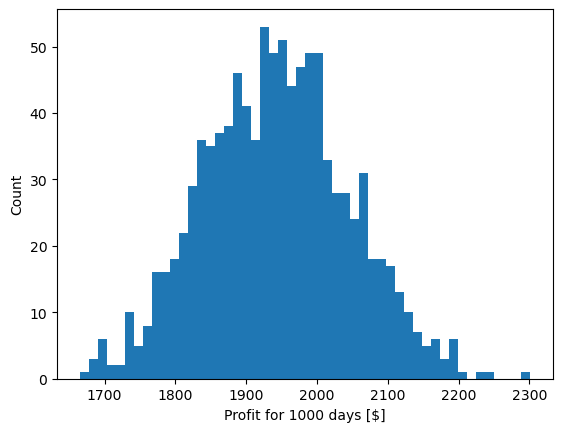

In [8]:
profits_many_items = run_simulation_many_items()
plt.hist(profits_many_items, bins = 50)
plt.xlabel("Profit for " + str(days) + " days [$]")
plt.ylabel("Count")
plt.show()

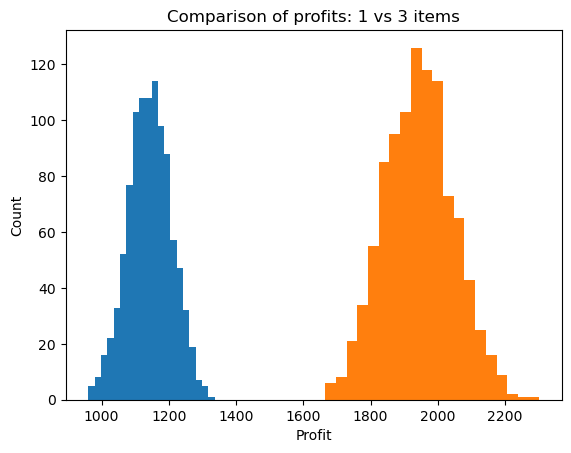

In [9]:
plt.title("Comparison of profits: 1 vs 3 items")
plt.hist(profits, bins = 20)
plt.hist(profits_many_items, bins = 20)
plt.xlabel("Profit")
plt.ylabel("Count")
plt.show()

### Problem 5. Image Convolution
"Convolution" refers to a process similar to "mixing" two functions. It can be performed in one dimension (e.g. on audio data), or many dimensions. In this problem, we'll look at 2D convolution of images and what we can do with it.

Let's first read an image. Once again, to make things easier, we'll separate the channels. We can work on all three channels separately or at once but it's easier to work with one channel only.

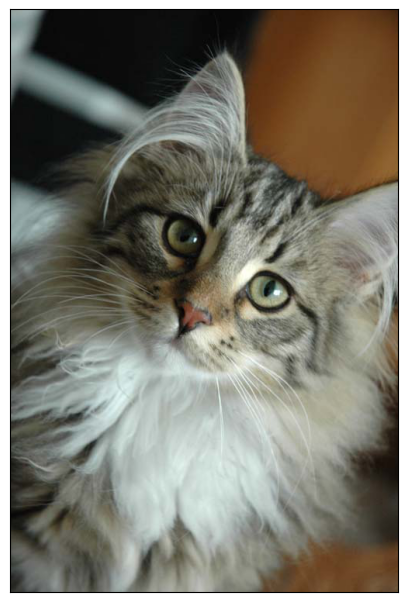

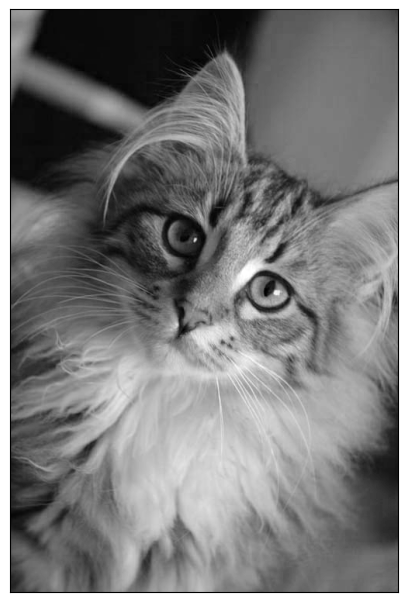

In [70]:
original_image = imread("Norwegian_Forest_Cat_Portrait.JFIF")

def display(image):
    # If there is only one channel to show, display it as grayscale
    cm = None
    if(len(image.shape)) == 2:
        cm = "gray"
    plt.figure(figsize = (5, 10))
    plt.imshow(image, cmap = cm)
    plt.xticks([])
    plt.yticks([])
    plt.show()

display(original_image)
r = original_image[:, :, 0]
display(r)

**Convolution** means taking a special square matrix (usually 3x3 or 5x5), called a **convolution kernel** and applying it to the image like this: the central pixel of the resulting image is the sum of element-wise products between the image and the kernel:
![Convolution example](convolution.png)

After that, the kernel moves 1px to the right and contiinues. It "slides" across the entire image. The edge pixels are a bit problematic but there are several ways to deal with that. The most common way is to copy whatever pixel value happened to be at the border.

![Border handling](border.png)

The algorithm is always the same. The output depends on the **kernel**. Different kernels produce different results: some detect edges (lines), others detect corners; some apply blurring and sharpening; some remove noise, etc.

The results can be useful for analyzing what's on the image, or just for artistic purposes.

Let's examine this filter, for example:

$$ F = \begin{bmatrix}
1/9 & 1/9 & 1/9 \\
1/9 & 1/9 & 1/9 \\
1/9 & 1/9 & 1/9
\end{bmatrix}
$$

This calculates the average of all surrounding pixels and basically smooths the image.

Note that in order to preserve brightness, the sum of all elements in $F$ must be equal to 1. If it's not, the image will be darker or brighter (which may or may not be a desired effect).

`scipy.ndimage` has a method for performing 1D and multi-dimensional convolution. Read the docs [here](https://docs.scipy.org/doc/scipy-0.15.1/reference/generated/scipy.ndimage.filters.convolve.html#scipy.ndimage.filters.convolve).

Apply the convolution. To see better how it performs, you can plot only a part of the image - this will zoom the entire thing. Compare the "before" and "after" images.

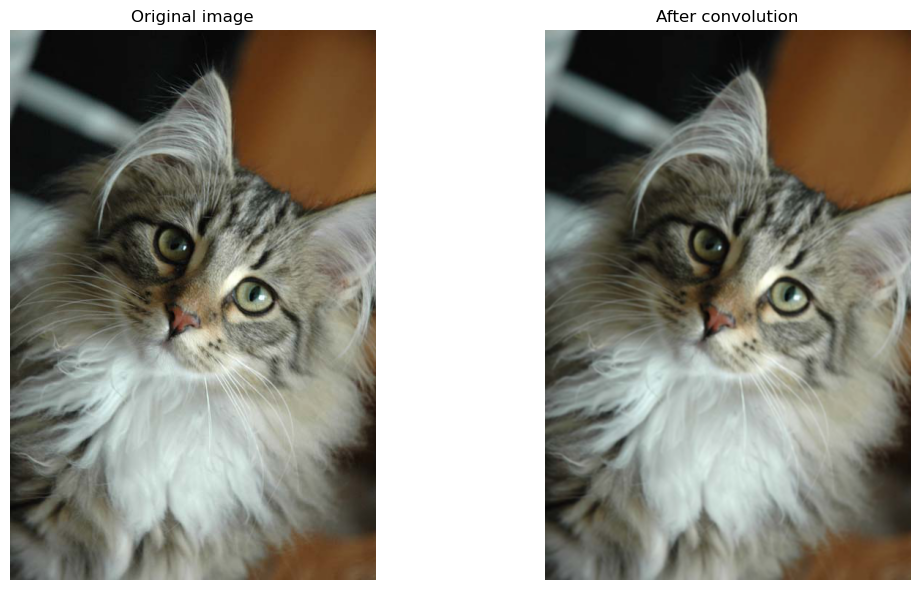

In [78]:
from PIL import Image
from scipy import ndimage

image = Image.open("Norwegian_Forest_Cat_Portrait.JFIF").convert("RGB")
image = np.array(image)

kernel = np.ones((3, 3)) / 9
blurred = ndimage.convolve(image.astype(float), kernel[:, :, None], mode='nearest')

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(image)
ax[0].set_title("Original image")
ax[1].imshow(np.clip(blurred, 0, 255).astype(np.uint8))
ax[1].set_title("After convolution")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

Play around with more kernels (they're also called **filters**). You can find examples on the Internet, or you can create your own. Have fun :).

Try these filters:
* Gaussian blur
* Sobel edge detector - vertical, horizontal
* Corner detector
* Gradient detector
* Sharpening
* Unsharp mask

For each filter, show the result before and after its application.

Sources: <a href="https://en.wikipedia.org/wiki/Kernel_(image_processing)">Wikipedia</a>, [Image Kernels explained visually](http://setosa.io/ev/image-kernels/).

**Optional:** Think about you might use edge, corner and gradient detectors in image processing.

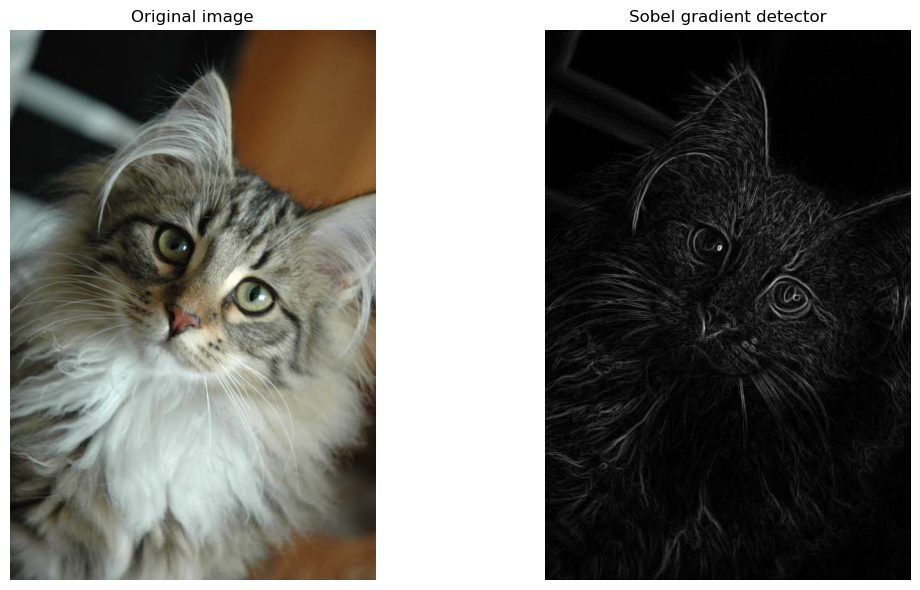

In [80]:
# Write your code here
gray = np.mean(image[:, :, :3], axis=2)

gx = ndimage.sobel(gray, axis=1)
gy = ndimage.sobel(gray, axis=0)

gradient = np.hypot(gx, gy)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(image)
ax[0].set_title("Original image")

ax[1].imshow(gradient, cmap="gray")
ax[1].set_title("Sobel gradient detector")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

### ** Problem 6. Monte Carlo Simulation
One common technique to apply simulations is called **Monte Carlo simulation**. It's similar to the simulation from the previous example. The main idea is to use random sampling to solve deterministic problems.

Research what these simulations are. Give examples. Implement at least one case of a Monte Carlo simulation. You can use the following checklist to help with your research and work:
* What is a simulation?
    * How is simulation used in science?
    * Why is a simulation useful?
* How are statistics useful in simulation? How can we simulate unknown, random processes?
* What is a Monte Carlo simulation (also known as "Monte Carlo method")?
* A common use of Monte Carlo methods is numeric integration
    * Define the problem. Propose the solution. Implement it and test with some common functions
    * How does this method compare to other methods, e.g. the trapezoidal rule? Compare the performance (accuracy and time to execute) of both methods
* Apply Monte Carlo simulation to a real-life system. There are many examples. You can see [Wikipedia](https://en.wikipedia.org/wiki/Monte_Carlo_method#Applications) or some other resource for inspiration.

Use a library, like PyMC3, to make an in-depth analysis. If you're additionally interested in the topic, look up "probabilistic programming".

***Here is a Monte Carlo simulation that estimates $\pi$ by randomly placing points inside a square and counting how many fall inside an inscribed circle.***

How it works:
- Generate random points within a square of area 4.
- Count points inside the unit circle, whose area is $\pi$.
- Estimate $\pi$ as $4 \times \frac{\text{points inside}}{\text{total points}}$.

Estimated pi: 3.1464
Actual pi: 3.141592653589793


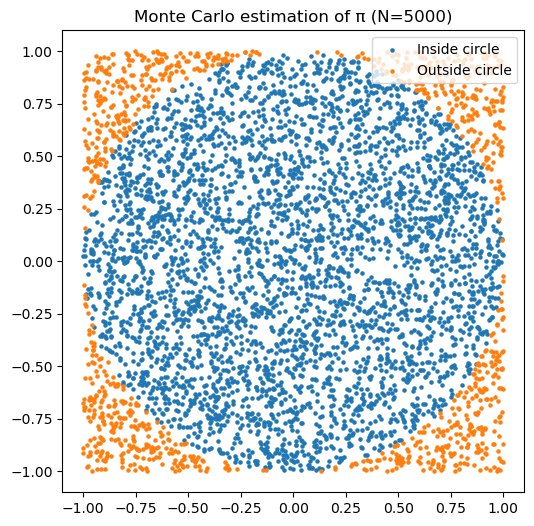

In [81]:
N = 5000
rng = np.random.default_rng(42)

x, y = rng.uniform(-1, 1, (2, N))
inside = x**2 + y**2 <= 1

print("Estimated pi:", 4 * inside.mean())
print("Actual pi:", np.pi)

plt.figure(figsize=(6, 6))
plt.scatter(x[inside], y[inside], s=5, label="Inside circle")
plt.scatter(x[~inside], y[~inside], s=5, label="Outside circle")
plt.gca().set_aspect("equal")
plt.title(f"Monte Carlo estimation of π (N={N})")
plt.legend()
plt.show()

### ** Problem 7. Classification
A type of widely used **models** is **classification**. Regression outputs a continuous value while classification outputs one of several pre-defined classes. In the most simple way, the classes are only two. For example, if we want to detect whether there's a cat on an image, we can have two classes: "cat" and "non-cat".

Explore the problem of classification. Implement and document one algorithm. Apply it to some real-world data. You can use the following checklist:

**Note:** If your paper is **about the algorithm**, consider **writing it from scratch**, not reusing it from a library.

* What is supervised learning? What do supervised learning models do?
* What is regression? What is classification?
* What types of problems does classification solve directly?
    * What types of problems can be reduced to classification?
* What's the difference between two-class and multi-class classification?
* Explore one algorithm for classification, e.g. logistic regression.
    * State the problem clearly
    * List all sssumptions of the modelling function
    * Describe the process: distances, error function, total loss, gradient descent, etc.; as needed
    * Implement the algorithm from scratch
* Select or generate a small dataset, suitable for classification. Run your algorithm as a sanity check
* Debug and solve any problems
* Waht is a confusion matrix?
* What metrics are used to score a classifier?
    * Accuracy, Precision, Recall, others
    * ROC curve, interpretation
* Select a real dataset
    * Explore it to get acquainted with what information it contains
    * Clean up the data if you need to do so
    * Perform classification
    * Score your classification model
    * Use your classifier to predict
        * Split the data into training and testing set
        * Optionally, perform **cross-validation**
    * Compare your implementation to another one, e.g. `scikit-learn`. They should give the same (or very similar) results
    * Communicate the results on your dataset
    * Optionally, publish your model on the Internet as a Web API